In [1]:
import random
import statistics
import matplotlib.pyplot as plt

POPULATION_SIZE = 10
ITERATIONS = 50
NUM_RUNS = 1000
FIRST_SEED = 100000
LOWER_BOUND = -5
UPPER_BOUND = 10
GAP_TOLERANCE = 1e-3
SPREAD_TOLERANCE = 1e-3
CHANGE_TOLERANCE = 1e-12

def objective_function(x):
    return 10 - (x - 3)**2

def run_baseline(iterations=ITERATIONS):
    population = [
        random.uniform(LOWER_BOUND, UPPER_BOUND)
        for _ in range(POPULATION_SIZE)
    ]
    populations = [population]

    for _ in range(iterations):
        new_population = []
        for _ in range(POPULATION_SIZE):
            xa, xb, xc = random.sample(population, 3)
            c = (xa + xb + xc) / 3
            xp = max(
                [xa, xb, xc],
                key=objective_function
            )
            r = random.uniform(0, 1.2)
            xnew = c + r * (xp - c)
            xnew = max(LOWER_BOUND, min(UPPER_BOUND, xnew))
            new_population.append(xnew)
        population = new_population
        populations.append(population)

    return populations

runs = []
for seed in range(FIRST_SEED, FIRST_SEED + NUM_RUNS):
    random.seed(seed)
    runs.append(run_baseline())

In [2]:
def summarize(populations):
    population_best = [
        max(objective_function(x) for x in population)
        for population in populations
    ]
    best_so_far = [
        max(population_best[:i + 1])
        for i in range(len(population_best))
    ]
    spread = [statistics.stdev(population) for population in populations]
    return population_best, best_so_far, spread

summaries = [summarize(populations) for populations in runs]
final_best = [summary[1][-1] for summary in summaries]

In [3]:
failed = [i for i, value in enumerate(final_best) if 10 - value >= GAP_TOLERANCE]

last_improvement = [
    max(
        (k for k in range(1, ITERATIONS + 1)
         if summaries[i][1][k] > summaries[i][1][k - 1] + CHANGE_TOLERANCE),
        default=0
    )
    for i in failed
]
small_spread = [
    next(k for k, value in enumerate(summaries[i][2]) if value < SPREAD_TOLERANCE)
    for i in failed
]
inside_range = sum(min(runs[i][0]) <= 3 <= max(runs[i][0]) for i in failed)

improved_later = 0
for i in failed:
    random.seed(FIRST_SEED + i)
    longer_best = summarize(run_baseline(4 * ITERATIONS))[1][-1]
    if longer_best > final_best[i] + CHANGE_TOLERANCE:
        improved_later += 1

In [4]:
decreases = [
    summary[0][k] - summary[0][k + 1]
    for summary in summaries
    for k in range(ITERATIONS)
    if summary[0][k] - summary[0][k + 1] > CHANGE_TOLERANCE
]
runs_with_large_decrease = sum(
    any(summary[0][k] - summary[0][k + 1] > GAP_TOLERANCE for k in range(ITERATIONS))
    for summary in summaries
)
final_loss = [summary[1][-1] - summary[0][-1] for summary in summaries]
total_iterations = NUM_RUNS * ITERATIONS

MEDIAN STD OF x IN THE POPULATION
Iteration  0: 4.299e+00
Iteration  1: 1.914e+00
Iteration  2: 7.610e-01
Iteration  3: 3.150e-01
Iteration  5: 7.069e-02
Iteration 10: 2.276e-03
Iteration 20: 5.084e-06
Iteration 50: 3.187e-13


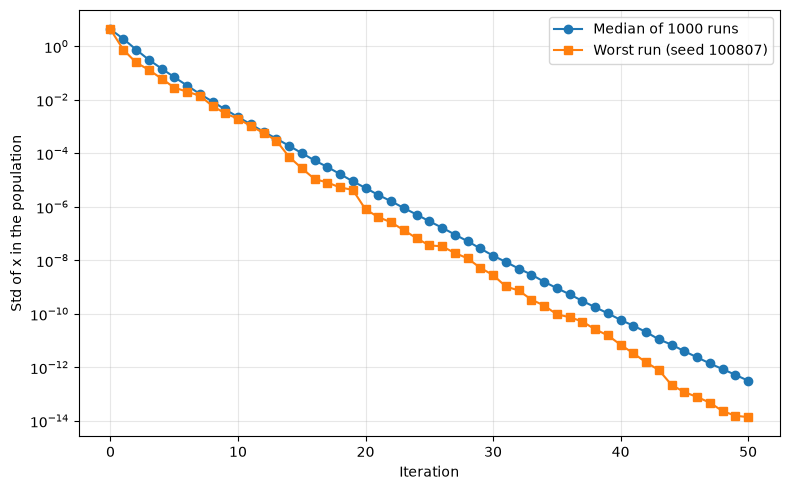

In [5]:
worst = min(range(NUM_RUNS), key=lambda i: final_best[i])
median_spread = [
    statistics.median(summary[2][k] for summary in summaries)
    for k in range(ITERATIONS + 1)
]

print("MEDIAN STD OF x IN THE POPULATION")
for k in (0, 1, 2, 3, 5, 10, 20, ITERATIONS):
    print(f"Iteration {k:>2}: {median_spread[k]:.3e}")

plt.figure(figsize=(8, 5))
plt.plot(
    range(ITERATIONS + 1),
    median_spread,
    marker="o",
    label=f"Median of {NUM_RUNS} runs"
)
plt.plot(
    range(ITERATIONS + 1),
    summaries[worst][2],
    marker="s",
    label=f"Worst run (seed {FIRST_SEED + worst})"
)
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Std of x in the population")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

WORST RUN (seed 100807)
 Iteration  Population best  Best so far   Std of x   Mean x
         0         4.514217     4.514217  4.264e+00   0.3220
         1         4.463829     4.514217  7.565e-01  -0.1452
         2         3.786642     4.514217  2.493e-01   0.1855
         3         3.605342     4.514217  1.331e-01   0.2851
         5         3.535514     4.514217  2.880e-02   0.4183
        10         3.495985     4.514217  1.970e-03   0.4476
        20         3.494891     4.514217  8.059e-07   0.4495
        50         3.494890     4.514217  1.389e-14   0.4495
Final population: x = 0.4495
Decreases of the population best: 28 of 50 iterations


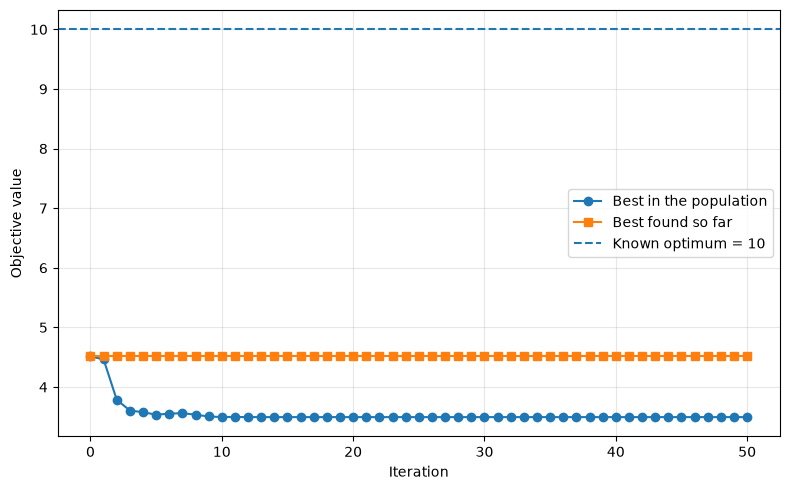

In [6]:
population_best, best_so_far, spread = summaries[worst]
final_population = runs[worst][-1]
decreases_in_run = sum(
    population_best[k] - population_best[k + 1] > CHANGE_TOLERANCE
    for k in range(ITERATIONS)
)

print(f"WORST RUN (seed {FIRST_SEED + worst})")
print(f"{'Iteration':>10} {'Population best':>16} {'Best so far':>12} {'Std of x':>10} {'Mean x':>8}")
for k in (0, 1, 2, 3, 5, 10, 20, ITERATIONS):
    print(
        f"{k:>10} {population_best[k]:>16.6f} {best_so_far[k]:>12.6f} "
        f"{spread[k]:>10.3e} {statistics.mean(runs[worst][k]):>8.4f}"
    )
print(f"Final population: x = {max(final_population, key=objective_function):.4f}")
print(f"Decreases of the population best: {decreases_in_run} of {ITERATIONS} iterations")

plt.figure(figsize=(8, 5))
plt.plot(
    range(ITERATIONS + 1),
    population_best,
    marker="o",
    label="Best in the population"
)
plt.plot(
    range(ITERATIONS + 1),
    best_so_far,
    marker="s",
    label="Best found so far"
)
plt.axhline(
    y=10,
    linestyle="--",
    label="Known optimum = 10"
)
plt.xlabel("Iteration")
plt.ylabel("Objective value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()